# Atropelamentos em São Paulo: modelo de risco de **ocorrência** (onde e quando)

**Pré-requisitos:** notebooks 01 (bases tratadas) e 05 (baixa a chuva horária do Open-Meteo).
**Spec:** `docs/specs/2026-11-11-modelo-risco-design.md`.

**Pergunta:** neste local (célula de ~500 m), nesta hora, neste tipo de dia e com ou sem chuva, **quantos
atropelamentos são esperados por hora?** É o risco que o nó usa para agir **antes** (prevenção). A gravidade
(notebook 05) passa a ser coadjuvante: diz a chance de um atropelamento, se acontecer, ser fatal.

**Por que não é o mesmo problema do notebook 05.** Lá, a unidade era o atropelamento que **já aconteceu**. Aqui,
a unidade é **local × momento**, incluindo os momentos em que **nada aconteceu**. Só assim dá para medir uma
**taxa**: por exemplo, atropelamentos por hora chuvosa × por hora seca (a meta-análise de Qiu e Nixon, 2008, mede o
efeito do tempo sobre a **frequência** de sinistros, que é isto).

## 1. Configuração e dados

In [1]:
from pathlib import Path
import sys, datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import statsmodels.api as sm
from sklearn.linear_model import PoissonRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)

def achar_raiz(inicio: Path = Path.cwd()) -> Path:
    for p in [inicio, *inicio.parents]:
        if (p / "data" / "raw").is_dir():
            return p
    raise FileNotFoundError("pasta data/raw não encontrada acima de " + str(inicio))
ROOT = achar_raiz()
RAW, PROCESSED, EVID = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "docs" / "evidencias" / "estudo_b"
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT / "src" / "estudo_b_risco_vida"))
import risco as rv   # mesmas funções que a risco() usa em produção

SEED = 42
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.edgecolor": "#bdbcb6",
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
salvar = lambda fig, nome: fig.savefig(EVID / nome, dpi=150, bbox_inches="tight", facecolor="white")

atrop = pd.read_parquet(PROCESSED / "atropelamentos_sp_2022_2025.parquet")
chuva_bruta = pd.read_csv(RAW / "open_meteo_precipitacao_sp_2022_2025.csv", parse_dates=["hora_local"]).set_index("hora_local")["precipitacao_mm"]
chuva_h = rv.chuva_por_hora(chuva_bruta)          # índice = início da hora

ev = atrop[atrop["hora"].notna() & atrop["coord_valida"]].copy()
ev["quando"] = ev["data_sinistro"] + pd.to_timedelta(ev["hora"].astype(float), unit="h")
ev["chuva_mm"] = chuva_h.reindex(ev["quando"]).to_numpy()
ev = ev[ev["chuva_mm"].notna()].reset_index(drop=True)
ev["ano"] = ev["quando"].dt.year
CELULAS = sorted(set(rv.celula(ev["latitude"], ev["longitude"])))
print(f"atropelamentos com hora e coordenada: {len(ev):,} | células com ≥ 1 caso em 2022–2025: {len(CELULAS):,}")
ev.groupby("ano").size().rename("atropelamentos").to_frame().T

atropelamentos com hora e coordenada: 15,563 | células com ≥ 1 caso em 2022–2025: 2,951


ano,2022,2023,2024,2025
atropelamentos,4071,4115,4301,3076


## 2. A chuva muda a **frequência** de atropelamentos?

Primeiro a conta simples para a cidade: atropelamentos ÷ horas, com chuva e sem chuva (2022–2024; 2025 fica de
fora por estar incompleto). Depois a mesma razão **ajustada pela hora e pelo tipo de dia** (Mantel-Haenszel): chove
mais à tarde, que já é o horário com mais atropelamentos, e a conta simples misturaria os dois efeitos.

In [2]:
base_ch = ev[ev["ano"].between(2022, 2024)]
expo_ch = rv.exposicao(chuva_h, "2022-01-01", "2024-12-31")
cnt = (rv.contagens(base_ch).groupby(["hora", "fim_de_semana", "chovendo"])["n"].sum()
       .reindex(expo_ch.set_index(["hora", "fim_de_semana", "chovendo"]).index, fill_value=0))
e = expo_ch.set_index(["hora", "fim_de_semana", "chovendo"]).assign(n=cnt)

tot = e.groupby(level="chovendo")[["n", "horas"]].sum()
tot["atropelamentos por hora"] = tot["n"] / tot["horas"]
ic = lambda n, h: (n / h * np.exp(-1.96 / np.sqrt(n)), n / h * np.exp(1.96 / np.sqrt(n)))
tot["IC 95%"] = [f"{a:.3f}–{b:.3f}" for a, b in (ic(n, h) for n, h in zip(tot["n"], tot["horas"]))]
tot.index = ["sem chuva", "chovendo"]
rr_bruta = tot["atropelamentos por hora"].iloc[1] / tot["atropelamentos por hora"].iloc[0]

# Mantel-Haenszel por estrato hora × tipo de dia
s = pd.concat({"n": e["n"].unstack("chovendo"), "h": e["horas"].unstack("chovendo")}, axis=1).fillna(0)
s.columns = [f"{c}_{a}" for a, c in s.columns]
T = s["0_h"] + s["1_h"]
rr_mh = (s["1_n"] * s["0_h"] / T).sum() / (s["0_n"] * s["1_h"] / T).sum()
display(tot.round(4))
print(f"razão de taxas chuva ÷ seco: bruta = {rr_bruta:.2f} | ajustada por hora e tipo de dia (Mantel-Haenszel) = {rr_mh:.2f}")

,n,horas,atropelamentos por hora,IC 95%
sem chuva,10879,22972,0.4736,0.465–0.483
chovendo,1608,3332,0.4826,0.460–0.507


razão de taxas chuva ÷ seco: bruta = 1.02 | ajustada por hora e tipo de dia (Mantel-Haenszel) = 0.88


**Leitura: medida do jeito certo (por hora), a chuva também não aumenta os atropelamentos registrados.**

- Com chuva: 0,483 atropelamentos por hora na cidade (IC 0,460–0,507). Sem chuva: 0,474 (IC 0,465–0,483). A
  razão bruta é **1,02**.
- Ajustando pela hora e pelo tipo de dia (Mantel-Haenszel), a razão cai para **0,88**: no mesmo horário, chovendo
  há até um pouco **menos** atropelamentos registrados.
- Isso não contradiz a meta-análise de Qiu e Nixon, que acha mais **sinistros** na chuva (sobretudo colisões
  entre veículos). Para **atropelamentos** há uma explicação plausível: com chuva há **menos pedestres na rua**
  (menor exposição), o que compensa a visibilidade e a frenagem piores. Há também a limitação conhecida: um único
  ponto de chuva para a cidade toda.

**Consequência:** o modo "chuva" do nó continua justificado por **alagamento e visibilidade**, não por "mais
atropelamentos". A `risco()` não mostra "chuva" como motivo, porque o efeito não é demonstrado (IC do
multiplicador da Poisson: 0,85–1,02).

## 3. O painel: célula × hora × tipo de dia × chuva

**Sem vazamento:** as variáveis do local (histórico, grupo do DBSCAN, peso, rodovia) não podem vir do mesmo
período que o alvo, senão "histórico da célula" já contém os atropelamentos que o modelo deve prever. Por isso:

| Conjunto | Variáveis do local calculadas com | Alvo (atropelamentos contados) |
|---|---|---|
| **treino** (seleção e ajuste) | 2022 | 2023 |
| **teste** | 2022–2023 | 2024 |
| **checagem** (não fatais incompletos) | 2022–2023 | 2025 |

Histórico e peso entram **por ano**, e o limiar do DBSCAN (`min_samples`, em peso) **cresce com o número de anos**
(`tabela_celulas(..., anos=…)`): com o dobro de dados e o mesmo limiar, muito mais células virariam "grupo", e a
variável `em_grupo` mudaria de sentido entre o treino (1 ano) e o teste/produção (2 anos). Cada linha tem `n` (atropelamentos) e `horas` (quantas horas daquele tipo houve no ano).

In [3]:
COLS = ["latitude", "longitude", "fatal", "tipo_via"]
tab22 = rv.tabela_celulas(ev.loc[ev["ano"] == 2022, COLS], anos=1)
tab2223 = rv.tabela_celulas(ev.loc[ev["ano"].isin([2022, 2023]), COLS], anos=2)
print(f"células em grupo do DBSCAN: {tab22['em_grupo'].mean():.1%} (histórico 2022) × {tab2223['em_grupo'].mean():.1%} (2022–23)")

def painel(ano: int, tab: pd.DataFrame) -> pd.DataFrame:
    expo = rv.exposicao(chuva_h, f"{ano}-01-01", f"{ano}-12-31")
    p = pd.DataFrame({"celula": pd.Series(CELULAS, dtype=object)}).merge(expo, how="cross")
    c = rv.contagens(ev[ev["ano"] == ano])
    p = p.merge(c, on=["celula", "hora", "fim_de_semana", "chovendo"], how="left").fillna({"n": 0})
    X = rv.montar_variaveis_risco(p["celula"].tolist(), p["hora"], p["fim_de_semana"], p["chovendo"], tab)
    return pd.concat([p.reset_index(drop=True), X.drop(columns=["fim_de_semana", "chovendo"])], axis=1)

P_tr, P_te, P_ex = painel(2023, tab22), painel(2024, tab2223), painel(2025, tab2223)
X_ = lambda P: P[rv.RISCO_VARIAVEIS]
pd.DataFrame({n: {"linhas": len(P), "atropelamentos": int(P["n"].sum()), "% linhas com zero": round((P["n"] == 0).mean() * 100, 1),
                  "horas no ano": int(P.drop_duplicates(["hora", "fim_de_semana", "chovendo"])["horas"].sum())}
              for n, P in [("treino (alvo 2023)", P_tr), ("teste (alvo 2024)", P_te), ("checagem (alvo 2025)", P_ex)]}).T

células em grupo do DBSCAN: 0.5% (histórico 2022) × 0.2% (2022–23)


,linhas,atropelamentos,% linhas com zero,horas no ano
treino (alvo 2023),283296.0,4115.0,98.6,8760.0
teste (alvo 2024),283296.0,4301.0,98.5,8784.0
checagem (alvo 2025),283296.0,3076.0,99.0,8759.0


## 4. Modelos e escolha (validação cruzada só no treino)

1. **Linha de base** — o que já se sabe olhando o mapa: taxa histórica da célula (com +0,1 caso para não zerar) ×
   perfil médio da cidade por hora e tipo de dia.
2. **Regressão de Poisson** — `PoissonRegressor` (scikit-learn) sobre as variáveis padronizadas, alvo = taxa por hora,
   peso = horas (equivale ao offset log(horas)). Para os **multiplicadores com IC**, o mesmo modelo é ajustado no
   statsmodels.
3. **Gradient boosting com perda de Poisson** — `HistGradientBoostingRegressor(loss="poisson")`, mesmo alvo e peso;
   grade pequena de hiperparâmetros.

**Validação cruzada:** 5 dobras **agrupadas por célula** (`GroupKFold`): uma célula nunca está no ajuste e na
validação ao mesmo tempo. **Métrica:** deviance de Poisson média sobre as contagens (menor = melhor).
**Regra fixada antes do teste:** menor deviance; diferença < 1% → fica a Poisson.

In [4]:
def deviance(n, mu):
    n, mu = np.asarray(n, float), np.maximum(np.asarray(mu, float), 1e-12)
    return float(2 * np.mean(np.where(n > 0, n * np.log(np.where(n > 0, n, 1) / mu), 0) - (n - mu)))

def linha_de_base(P, anos_hist):
    hist = ev[ev["ano"].isin(anos_hist)]
    expo = rv.exposicao(chuva_h, f"{min(anos_hist)}-01-01", f"{max(anos_hist)}-12-31")
    H = expo["horas"].sum()
    n_cel = pd.Series(rv.celula(hist["latitude"], hist["longitude"])).value_counts()
    taxa_cel = (P["celula"].map(n_cel).fillna(0).to_numpy() + 0.1) / H
    eh = expo.groupby(["hora", "fim_de_semana"])["horas"].sum()
    ec = rv.contagens(hist).groupby(["hora", "fim_de_semana"])["n"].sum().reindex(eh.index, fill_value=0)
    perfil = (ec / eh) / (ec.sum() / H)
    taxa = taxa_cel * perfil.reindex(pd.MultiIndex.from_arrays([P["hora"], P["fim_de_semana"]])).to_numpy()
    return taxa * P["horas"].to_numpy()   # contagem esperada = taxa por hora × horas

y_tr, w_tr = (P_tr["n"] / P_tr["horas"]).to_numpy(), P_tr["horas"].to_numpy()
grupos_cv = pd.factorize(P_tr["celula"].astype(str))[0]
gkf = GroupKFold(n_splits=5)
candidatos = {"regressão de Poisson": lambda: make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-6, max_iter=3000, tol=1e-10))}
for lr in [0.05, 0.1]:
    for folhas in [15, 31]:
        for minimo in [50, 200]:
            candidatos[f"boosting lr={lr} folhas={folhas} min={minimo}"] = (
                lambda lr=lr, folhas=folhas, minimo=minimo: HistGradientBoostingRegressor(
                    loss="poisson", learning_rate=lr, max_leaf_nodes=folhas, min_samples_leaf=minimo, max_iter=300,
                    early_stopping=False, random_state=SEED))

def ajustar(fabrica, X, y, w):
    m = fabrica()
    if isinstance(m, HistGradientBoostingRegressor):
        return m.fit(X, y, sample_weight=w)
    return m.fit(X, y, poissonregressor__sample_weight=w)

mu_base_tr = linha_de_base(P_tr, [2022])
# verificação: a linha de base precisa prever a ordem de grandeza certa (bug já visto: taxa sem × horas)
assert 0.8 < mu_base_tr.sum() / P_tr["n"].sum() < 1.25, mu_base_tr.sum() / P_tr["n"].sum()
cv = {nome: [] for nome in ["linha de base", *candidatos]}
for tr, va in gkf.split(P_tr, groups=grupos_cv):
    cv["linha de base"].append(deviance(P_tr["n"].iloc[va], mu_base_tr[va]))
    for nome, fab in candidatos.items():
        m = ajustar(fab, X_(P_tr).iloc[tr], y_tr[tr], w_tr[tr])
        cv[nome].append(deviance(P_tr["n"].iloc[va], m.predict(X_(P_tr).iloc[va]) * w_tr[va]))
cv_tab = pd.DataFrame({"deviance média (CV)": {k: np.mean(v) for k, v in cv.items()},
                       "± dp": {k: np.std(v) for k, v in cv.items()}}).sort_values("deviance média (CV)")
melhor_boost = cv_tab.drop(["linha de base", "regressão de Poisson"]).index[0]
d_pois, d_boost = cv_tab.loc["regressão de Poisson", "deviance média (CV)"], cv_tab.loc[melhor_boost, "deviance média (CV)"]
FINAL = melhor_boost if d_boost < d_pois * 0.99 else "regressão de Poisson"
print(f"melhor boosting: {melhor_boost} | escolhido pela regra: {FINAL}")
cv_tab.round(5)

melhor boosting: boosting lr=0.05 folhas=15 min=200 | escolhido pela regra: boosting lr=0.05 folhas=15 min=200


,deviance média (CV),± dp
boosting lr=0.05 folhas=15 min=200,0.10171,0.00302
boosting lr=0.05 folhas=15 min=50,0.10186,0.00294
boosting lr=0.1 folhas=15 min=200,0.10248,0.00316
boosting lr=0.05 folhas=31 min=200,0.10256,0.00313
boosting lr=0.1 folhas=15 min=50,0.10266,0.00296
boosting lr=0.05 folhas=31 min=50,0.10268,0.00313
boosting lr=0.1 folhas=31 min=200,0.10403,0.00351
boosting lr=0.1 folhas=31 min=50,0.10448,0.00317
linha de base,0.11068,0.00342
regressão de Poisson,0.57088,0.93772


In [5]:
modelo = ajustar(candidatos[FINAL], X_(P_tr), y_tr, w_tr)
poisson = ajustar(candidatos["regressão de Poisson"], X_(P_tr), y_tr, w_tr)   # também avaliada no teste, para comparar
glm = sm.GLM(P_tr["n"], sm.add_constant(X_(P_tr)), family=sm.families.Poisson(), offset=np.log(P_tr["horas"])).fit()
# verificação: o PoissonRegressor precisa ter sido ajustado de fato (bug já visto: parava na iteração 0 com a
# tolerância padrão e devolvia só a média) e coincidir com o statsmodels
assert poisson[-1].n_iter_ > 0
assert np.corrcoef(poisson.predict(X_(P_tr)), glm.predict(sm.add_constant(X_(P_tr)), offset=np.zeros(len(P_tr))))[0, 1] > 0.99
mult = pd.DataFrame({"multiplicador": np.exp(glm.params), "IC95_inf": np.exp(glm.conf_int()[0]),
                     "IC95_sup": np.exp(glm.conf_int()[1]), "p_valor": glm.pvalues}).drop("const")
CHUVA_RR = {"rr": float(mult.loc["chovendo", "multiplicador"]), "ic_inf": float(mult.loc["chovendo", "IC95_inf"]),
            "ic_sup": float(mult.loc["chovendo", "IC95_sup"])}
print("multiplicadores da regressão de Poisson (statsmodels, treino) — efeito de +1 na variável:")
mult.round(3)

multiplicadores da regressão de Poisson (statsmodels, treino) — efeito de +1 na variável:


,multiplicador,IC95_inf,IC95_sup,p_valor
hora_sin,0.609,0.580,0.638,0.000
hora_cos,0.541,0.512,0.570,0.000
hora_sin2,0.696,0.664,0.730,0.000
hora_cos2,0.809,0.773,0.848,0.000
fim_de_semana,0.756,0.703,0.813,0.000
chovendo,0.931,0.849,1.021,0.130
hist_log,2.387,2.278,2.500,0.000
em_grupo,1.198,0.788,1.820,0.398
peso_grupo,1.011,0.988,1.035,0.343
rodovia,0.634,0.470,0.855,0.003


**Leitura (validação cruzada e multiplicadores):**

- O **gradient boosting** tem a menor deviance (0,1017) e é escolhido pela regra fixada. Ele fica **8% abaixo da
  linha de base** (0,1107).
- A **regressão de Poisson** fica instável na validação: em uma das dobras, a extrapolação exponencial em células
  com peso de grupo fora do que ela viu explode a previsão (média 0,57 ± 0,94). Esse é outro motivo para não
  usá-la na produção. Ela continua útil para **explicar**:
  - o **histórico da célula** é o fator dominante: cada +1 em log(1 + atropelamentos por ano) multiplica o risco
    por **2,4**;
  - a **hora** tem efeito forte (os harmônicos captam os picos da manhã e da tarde);
  - **fim de semana** reduz o risco em 24% (×0,76);
  - células de **rodovia** têm 37% menos atropelamentos por hora (×0,63), embora sejam mais letais (notebook 05);
  - a **chuva** não tem efeito significativo (×0,93; IC 0,85–1,02; p = 0,13).

## 5. Teste (2024): o modelo prevê melhor que o mapa histórico?

In [6]:
mu = {"linha de base": linha_de_base(P_te, [2022, 2023]),
      "regressão de Poisson": poisson.predict(X_(P_te)) * P_te["horas"].to_numpy(),
      FINAL: modelo.predict(X_(P_te)) * P_te["horas"].to_numpy()}
n_te = P_te["n"].to_numpy()
obs_cel = P_te.groupby("celula")["n"].sum()
hist_cel = tab2223["hist_log"].reindex(obs_cel.index).fillna(0)

def captura(score_cel, frac):
    top = score_cel.sort_values(ascending=False).index[: max(1, int(round(len(score_cel) * frac)))]
    return obs_cel.loc[top].sum() / obs_cel.sum()

linhas = []
for nome, m in mu.items():
    cel = pd.Series(m, index=P_te.index).groupby(P_te["celula"]).sum().reindex(obs_cel.index)
    linhas.append({"modelo": nome, "deviance": deviance(n_te, m), "D² vs base": 1 - deviance(n_te, m) / deviance(n_te, mu["linha de base"]),
                   "captura top 1%": captura(cel, 0.01), "captura top 5%": captura(cel, 0.05),
                   "PAI top 5%": captura(cel, 0.05) / 0.05, "ROC-AUC (≥1 caso)": roc_auc_score(n_te > 0, m),
                   "PR-AUC (≥1 caso)": average_precision_score(n_te > 0, m),
                   "ROC-AUC sobre a taxa": roc_auc_score(n_te > 0, m / P_te["horas"].to_numpy()),
                   "PR-AUC sobre a taxa": average_precision_score(n_te > 0, m / P_te["horas"].to_numpy()),
                   "total previsto ÷ observado": m.sum() / n_te.sum()})
linhas.append({"modelo": "ranking só pelo histórico (2022–23)", "captura top 1%": captura(hist_cel, 0.01),
               "captura top 5%": captura(hist_cel, 0.05), "PAI top 5%": captura(hist_cel, 0.05) / 0.05})
res = pd.DataFrame(linhas).set_index("modelo")
print(f"teste 2024: {n_te.sum():,} atropelamentos em {len(obs_cel):,} células | linhas com ≥ 1 caso: {(n_te > 0).mean():.2%}")
res.round(3)

teste 2024: 4,301.0 atropelamentos em 2,951 células | linhas com ≥ 1 caso: 1.45%


,deviance,D² vs base,captura top 1%,captura top 5%,PAI top 5%,ROC-AUC (≥1 caso),PR-AUC (≥1 caso),ROC-AUC sobre a taxa,PR-AUC sobre a taxa,total previsto ÷ observado
modelo,,,,,,,,,,
linha de base,0.110,0.000,0.058,0.173,3.469,0.799,0.085,0.712,0.048,0.989
regressão de Poisson,0.105,0.048,0.056,0.172,3.441,0.825,0.085,0.738,0.052,0.966
boosting lr=0.05 folhas=15 min=200,0.104,0.052,0.057,0.174,3.488,0.828,0.085,0.737,0.050,0.991
ranking só pelo histórico (2022–23),NaN,NaN,0.058,0.173,3.469,NaN,NaN,NaN,NaN,NaN


In [7]:
r = res.loc[FINAL]
criterios = pd.DataFrame({
    "critério (fixado no spec)": ["D² > 0 contra a linha de base", "top 5% captura mais que o ranking histórico",
                                  "erro do total de 2024 ≤ 10%"],
    "valor": [f"{r['D² vs base']:.3f}", f"{r['captura top 5%']:.1%} × {res.loc['ranking só pelo histórico (2022–23)', 'captura top 5%']:.1%}",
              f"{(r['total previsto ÷ observado'] - 1):+.1%}"],
    "passou?": [r["D² vs base"] > 0, r["captura top 5%"] > res.loc["ranking só pelo histórico (2022–23)", "captura top 5%"],
                abs(r["total previsto ÷ observado"] - 1) <= 0.10]})
print(f"modelo final: {FINAL}")
criterios

modelo final: boosting lr=0.05 folhas=15 min=200


,critério (fixado no spec),valor,passou?
0,D² > 0 contra a linha de base,0.052,True
1,top 5% captura mais que o ranking histórico,17.4% × 17.3%,True
2,erro do total de 2024 ≤ 10%,-0.9%,True


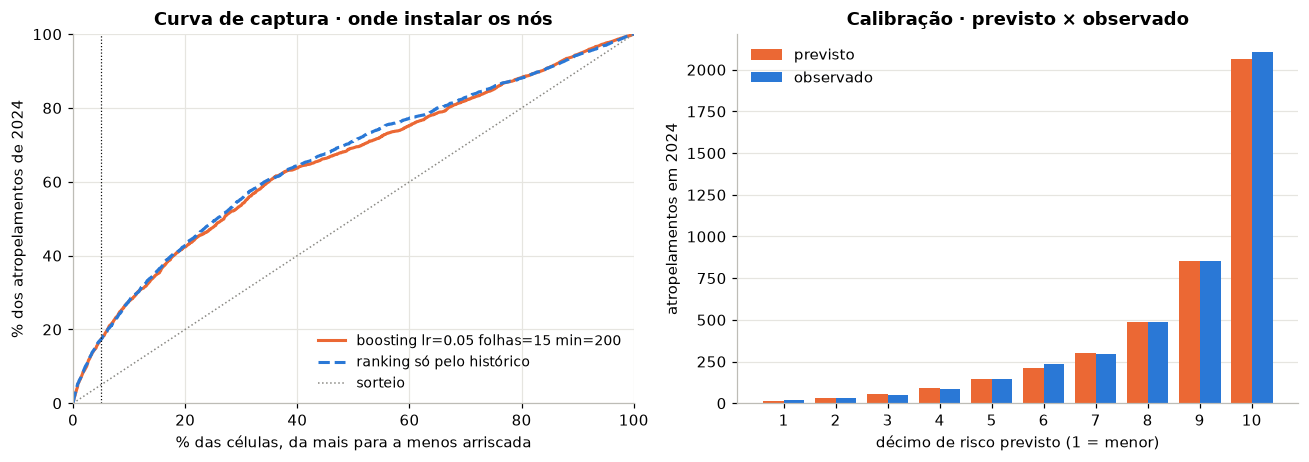

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
for nome, score, cor, ls in [(FINAL, pd.Series(mu[FINAL], index=P_te.index).groupby(P_te["celula"]).sum().reindex(obs_cel.index), LARANJA, "-"),
                             ("ranking só pelo histórico", hist_cel, AZUL, "--")]:
    o = obs_cel.loc[score.sort_values(ascending=False).index].cumsum() / obs_cel.sum()
    ax.plot(np.arange(1, len(o) + 1) / len(o) * 100, o.values * 100, color=cor, ls=ls, lw=2, label=nome)
ax.plot([0, 100], [0, 100], color=CINZA, lw=1, ls=":", label="sorteio")
ax.axvline(5, color="#0b0b0b", lw=0.8, ls=":")
ax.set_xlabel("% das células, da mais para a menos arriscada"); ax.set_ylabel("% dos atropelamentos de 2024")
ax.set_title("Curva de captura · onde instalar os nós"); ax.legend(frameon=False, fontsize=9); ax.set_xlim(0, 100); ax.set_ylim(0, 100)

ax = axes[1]
dec = pd.qcut(pd.Series(mu[FINAL]).rank(method="first"), 10, labels=False)
cal = pd.DataFrame({"previsto": mu[FINAL], "observado": n_te}).groupby(dec).sum()
x = np.arange(10)
ax.bar(x - 0.2, cal["previsto"], 0.4, color=LARANJA, label="previsto"); ax.bar(x + 0.2, cal["observado"], 0.4, color=AZUL, label="observado")
ax.set_xticks(x); ax.set_xticklabels([f"{i + 1}" for i in x]); ax.set_xlabel("décimo de risco previsto (1 = menor)")
ax.set_ylabel("atropelamentos em 2024"); ax.set_title("Calibração · previsto × observado"); ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
fig.tight_layout(); salvar(fig, "06_captura_calibracao.png"); plt.show()

In [9]:
mu_ex = modelo.predict(X_(P_ex)) * P_ex["horas"].to_numpy()
print(f"checagem 2025 (não fatais incompletos): total previsto ÷ observado = {mu_ex.sum() / P_ex['n'].sum():.2f} | "
      f"ROC-AUC = {roc_auc_score(P_ex['n'] > 0, mu_ex):.3f} | D² vs base = "
      f"{1 - deviance(P_ex['n'], mu_ex) / deviance(P_ex['n'], linha_de_base(P_ex, [2022, 2023])):.3f}")

checagem 2025 (não fatais incompletos): total previsto ÷ observado = 1.38 | ROC-AUC = 0.828 | D² vs base = 0.055


**Leitura (teste 2024): bem calibrado, um pouco melhor para dizer QUANDO, e igual ao histórico para dizer ONDE.**

| Critério do spec | Resultado | |
|---|---|---|
| D² > 0 contra a linha de base | **0,052** | ✅ 5% menos erro que o mapa histórico × perfil horário |
| top 5% captura mais que o ranking histórico | **17,4% × 17,3%** | ⚠️ "passa" por 0,1 ponto (≈ 4 atropelamentos): na prática é **empate** |
| erro do total de 2024 ≤ 10% | **−0,9%** | ✅ |

- **Onde:** o 5% de células mais arriscado concentra ~17% dos atropelamentos de 2024 (PAI 3,5: 3,5 vezes o
  acaso), **o mesmo que o ranking só pelo histórico**. As curvas de captura se sobrepõem. O melhor preditor de
  **onde** vai acontecer é **onde já aconteceu**, e a escolha dos pontos continua com o DBSCAN e o histórico.
- **Quando:** a unidade de avaliação é **célula × hora do dia × tipo de dia × chuva, somada no ano**, não uma hora
  específica. Ordenando essas linhas pela contagem esperada, a ROC-AUC sobe de 0,80 (base) para **0,83**, mas
  parte disso vem da **exposição** (combinações secas e de dia útil têm mais horas, para os dois modelos). Pela
  **taxa por hora**, sem o efeito da exposição, o ganho é menor e real: **0,74 × 0,71**. Na **PR-AUC**, a métrica
  mais exigente com tão poucos positivos (1,45% das linhas), o modelo **empata** com a base (0,085 × 0,085 pela
  contagem; 0,050 × 0,048 pela taxa). Resumindo: o modelo ordena um pouco melhor os momentos de risco, mas não
  é um salto sobre "histórico × perfil horário".
- **Quanto:** a calibração é **muito boa**: previsto e observado batem em todos os décimos de risco, e o total de
  2024 erra só 0,9%. As probabilidades da `risco()` são, portanto, **confiáveis em número**, e é isso que
  permite a estimativa de impacto no dia 18.
- **2025:** prevê 38% a mais do que foi registrado, coerente com os não fatais incompletos (notebook 01).

## 6. O risco no piloto ao longo do dia

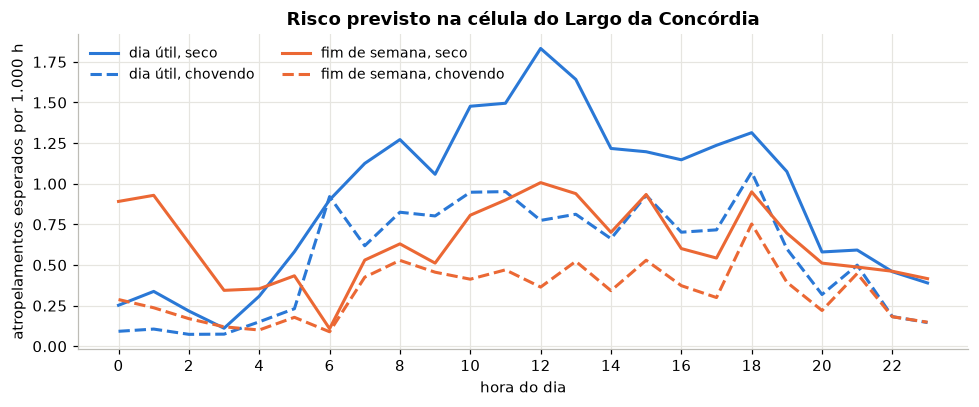

Largo, dia útil 18h seco: 1.3 por 1.000 h | média das células da cidade: 0.16 por 1.000 h


In [10]:
LARGO = (-23.54231, -46.61655)
c_largo = rv.celula([LARGO[0]], [LARGO[1]])[0]
grade = pd.DataFrame([(h, f, c) for h in range(24) for f in (0, 1) for c in (0, 1)], columns=["hora", "fim_de_semana", "chovendo"])
Xg = rv.montar_variaveis_risco([c_largo] * len(grade), grade["hora"], grade["fim_de_semana"], grade["chovendo"], tab2223)
grade["por 1000 h"] = modelo.predict(Xg) * 1000
fig, ax = plt.subplots(figsize=(9, 3.8))
for (f, c), d in grade.groupby(["fim_de_semana", "chovendo"]):
    ax.plot(d["hora"], d["por 1000 h"], color=LARANJA if f else AZUL, ls="--" if c else "-", lw=2,
            label=("fim de semana" if f else "dia útil") + (", chovendo" if c else ", seco"))
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hora do dia"); ax.set_ylabel("atropelamentos esperados por 1.000 h")
ax.set_title("Risco previsto na célula do Largo da Concórdia"); ax.legend(frameon=False, fontsize=9, ncol=2)
fig.tight_layout(); salvar(fig, "06_risco_piloto_por_hora.png"); plt.show()
media_cidade = (mu[FINAL].sum() / P_te["horas"].sum())
print(f"Largo, dia útil 18h seco: {grade.query('hora == 18 and fim_de_semana == 0 and chovendo == 0')['por 1000 h'].iloc[0]:.1f} por 1.000 h "
      f"| média das células da cidade: {media_cidade * 1000:.2f} por 1.000 h")

**Leitura (piloto):** no Largo da Concórdia, num dia útil seco às 18h, o modelo espera **1,3 atropelamento a cada
1.000 horas** na célula, cerca de **8 vezes a média das células com atropelamento registrado** (0,16). No dia útil,
o risco tem três picos: entrada no trabalho (7h–8h), almoço (12h) e saída (18h–19h). No fim de semana aparece um
pico de **madrugada (0h–1h)**, que conversa com a letalidade alta desse horário (notebook 05). Isso indica
**quando** o nó deve reforçar o modo "pedestre". As oscilações de uma hora para outra são em parte ruído do modelo
(poucos casos por hora numa célula só): vale olhar a **forma** da curva, não cada ponto.

## 7. Níveis de risco e exportação

`nivel` da `risco()` passa a vir **deste** modelo: cortes nos quantis **50%** e **90%** da taxa prevista no teste
2024, **ponderados pelas horas** (cada linha do painel vale as horas que representa). "Alto" = os 10% de
célula-horas mais arriscados da cidade.

In [11]:
lam_te = modelo.predict(X_(P_te)); w_te = P_te["horas"].to_numpy()
def quantil_ponderado(v, w, q):
    o = np.argsort(v); c = np.cumsum(w[o]) / w.sum()
    return float(v[o][np.searchsorted(c, q)])
CORTES = {"medio": quantil_ponderado(lam_te, w_te, 0.50), "alto": quantil_ponderado(lam_te, w_te, 0.90)}
LAMBDA_MEDIA = float((lam_te * w_te).sum() / w_te.sum())
nivel = np.where(lam_te >= CORTES["alto"], "alto", np.where(lam_te >= CORTES["medio"], "medio", "baixo"))
niv = pd.DataFrame({"nivel": nivel, "horas": w_te, "n": n_te}).groupby("nivel")[["horas", "n"]].sum().reindex(["baixo", "medio", "alto"])
niv["% das célula-horas"] = (niv["horas"] / niv["horas"].sum() * 100).round(1)
niv["% dos atropelamentos de 2024"] = (niv["n"] / niv["n"].sum() * 100).round(1)

hist_h = ev[ev["ano"].isin([2022, 2023])]
eh = rv.exposicao(chuva_h, "2022-01-01", "2023-12-31").query("fim_de_semana == 0").groupby("hora")["horas"].sum()
ch = rv.contagens(hist_h).query("fim_de_semana == 0").groupby("hora")["n"].sum()
HORAS_PICO = sorted((ch / eh).nlargest(2).index.astype(int).tolist())

# Células que nunca tiveram atropelamento em 2022–2025 estão fora da população do painel (viés de seleção: no painel,
# "sem histórico" quer dizer "teve caso depois"). Para elas a risco() usa a regra do meio caso: 0,5 ÷ horas observadas.
HORAS_OBS = float(rv.exposicao(chuva_h, "2022-01-01", "2025-12-31")["horas"].sum())
pacote = {"modelo": modelo, "nome_modelo": FINAL, "variaveis": rv.RISCO_VARIAVEIS, "tab_celula": tab2223,
          "celulas_modeladas": set(CELULAS), "taxa_celula_sem_registro": 0.5 / HORAS_OBS,
          "lambda_media": LAMBDA_MEDIA, "cortes_nivel": CORTES, "chuva_rr": CHUVA_RR, "horas_pico": HORAS_PICO,
          "metricas_teste": res.loc[FINAL].dropna().to_dict(), "historico": "2022–2023", "alvo_treino": "2023",
          "criado_em": dt.datetime.now().isoformat(timespec="seconds")}
joblib.dump(pacote, MODELS / "modelo_risco.joblib", compress=3)
print(f"cortes: médio ≥ {CORTES['medio'] * 1000:.3f} | alto ≥ {CORTES['alto'] * 1000:.3f} por 1.000 h | média = {LAMBDA_MEDIA * 1000:.3f} "
      f"| horas de pico (dia útil): {HORAS_PICO} | chuva: {CHUVA_RR}")
print(f"salvo: models/modelo_risco.joblib ({(MODELS / 'modelo_risco.joblib').stat().st_size / 1e6:.1f} MB)")
niv

cortes: médio ≥ 0.134 | alto ≥ 0.314 por 1.000 h | média = 0.164 | horas de pico (dia útil): [18, 19] | chuva: {'rr': 0.930964943210977, 'ic_inf': 0.8487232881796463, 'ic_sup': 1.021175850313615}
salvo: models/modelo_risco.joblib (0.2 MB)


,horas,n,% das célula-horas,% dos atropelamentos de 2024
nivel,,,,
baixo,12859146,955.0,49.6,22.2
medio,10447494,1988.0,40.3,46.2
alto,2614944,1358.0,10.1,31.6


**Leitura (níveis):** o nível **alto** cobre **10%** das combinações célula × hora × tipo de dia × chuva (pesadas pelas
horas) e concentrou **31,6%** dos atropelamentos de 2024, **3,1 vezes** o esperado se fosse ao acaso. O **baixo**
cobre metade e só 22% dos atropelamentos. Para a central: **acionar o nó nos períodos de nível alto** pega quase
1/3 dos atropelamentos em 1/10 do tempo × espaço monitorado (células com atropelamento registrado). É o argumento
de eficiência para o PDF.

## 8. Limitações

- **"Onde" não melhora além do histórico:** o critério 2 do spec não passou (empate). A escolha dos pontos de
  instalação continua pelo DBSCAN e pelo histórico (plano B para o "onde"). O modelo acrescenta o "quando" e o
  "quanto".
- **Treino com um ano de alvo:** para não vazar, as variáveis vêm de 2022 e o alvo de 2023 (o teste usa 2022–2023
  → 2024). Com mais anos, o modelo tende a ficar mais estável.
- **Só células que já tiveram atropelamento** entram no painel (~2.950). No painel, "sem histórico" quer dizer
  "teve caso depois", o que deixa essas células com risco mais alto (viés de seleção). Por isso, para um ponto cuja
  célula **nunca** teve atropelamento em 2022–2025 (inclusive fora de São Paulo), a `risco()` não usa o modelo:
  usa a regra do meio caso, 0,5 ÷ horas observadas (≈ 0,014 por 1.000 h), sempre nível "baixo". Um ponto novo
  que vire perigoso só aparece no modelo depois de entrar no histórico.
- **Exposição de pedestres desconhecida:** o modelo não sabe quantas pessoas passam em cada hora. Os "picos" de
  risco misturam mais pedestres com mais perigo por pedestre.
- **Chuva de um ponto só** para a cidade inteira; o efeito local da chuva pode ficar escondido.
- **Subnotificação:** atropelamentos leves sem boletim não aparecem (Abay, 2015; refs. 16–17 da bibliografia).
- **2025 incompleto:** serve só como checagem.